In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/cleaned_sales.csv")

df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 73100
Columns: 15


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Inventory Level,73100.0,274.469877,129.949514,50.00,162.00,273.000,387.0000,500.00
Units Sold,73100.0,136.464870,108.919406,0.00,49.00,107.000,203.0000,499.00
Units Ordered,73100.0,110.004473,52.277448,20.00,65.00,110.000,155.0000,200.00
Demand Forecast,73100.0,141.494720,109.254076,-9.99,53.67,113.015,208.0525,518.55
Price,73100.0,55.135108,26.021945,10.00,32.65,55.050,77.8600,100.00
Discount,73100.0,10.009508,7.083746,0.00,5.00,10.000,15.0000,20.00
Holiday/Promotion,73100.0,0.497305,0.499996,0.00,0.00,0.000,1.0000,1.00
Competitor Pricing,73100.0,55.146077,26.191408,5.03,32.68,55.010,77.8200,104.94


In [5]:
numerical_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

print("Numerical Columns:")
print(list(numerical_cols))

print("\nCategorical Columns:")
print(list(categorical_cols))

Numerical Columns:
['Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Holiday/Promotion', 'Competitor Pricing']

Categorical Columns:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']


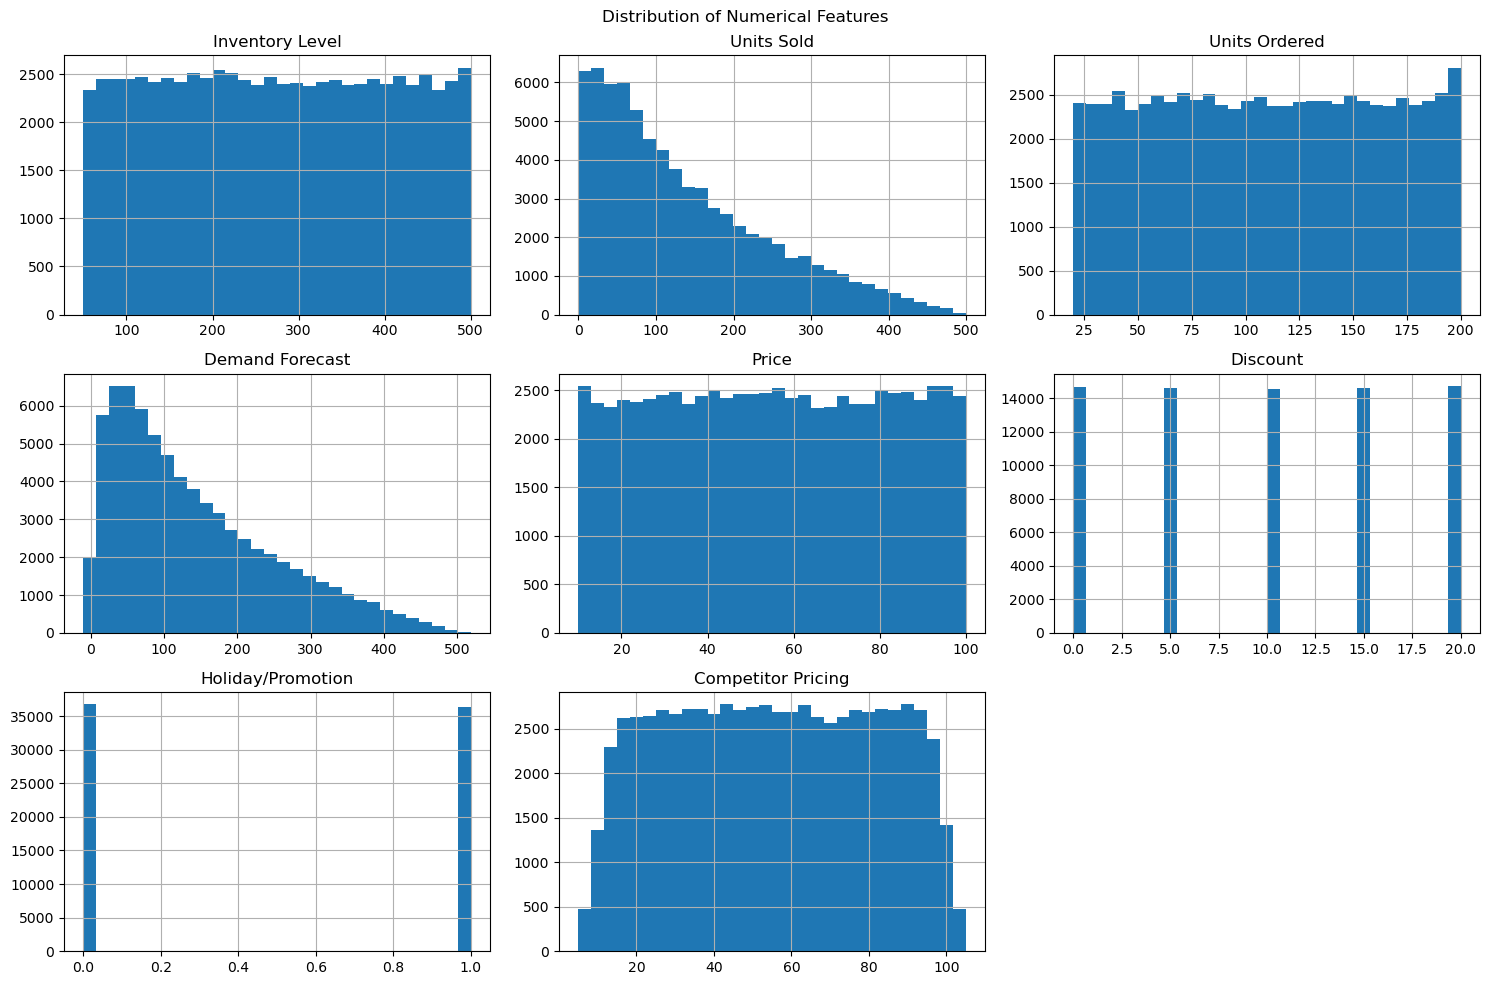

In [6]:
df[numerical_cols].hist(figsize=(15, 10), bins=30)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [7]:
for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].value_counts())


Column: Date
Date
2022-01-01    100
2023-04-26    100
2023-04-28    100
2023-04-29    100
2023-04-30    100
             ... 
2022-09-03    100
2022-09-04    100
2022-09-05    100
2022-09-06    100
2024-01-01    100
Name: count, Length: 731, dtype: int64

Column: Store ID
Store ID
S001    14620
S002    14620
S003    14620
S004    14620
S005    14620
Name: count, dtype: int64

Column: Product ID
Product ID
P0001    3655
P0002    3655
P0019    3655
P0018    3655
P0017    3655
P0016    3655
P0015    3655
P0014    3655
P0013    3655
P0012    3655
P0011    3655
P0010    3655
P0009    3655
P0008    3655
P0007    3655
P0006    3655
P0005    3655
P0004    3655
P0003    3655
P0020    3655
Name: count, dtype: int64

Column: Category
Category
Furniture      14699
Toys           14643
Clothing       14626
Groceries      14611
Electronics    14521
Name: count, dtype: int64

Column: Region
Region
East     18349
South    18297
North    18228
West     18226
Name: count, dtype: int64

Column: Weather 

In [8]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date Data Type:", df["Date"].dtype)
print("Minimum Date:", df["Date"].min())
print("Maximum Date:", df["Date"].max())

Date Data Type: datetime64[ns]
Minimum Date: 2022-01-01 00:00:00
Maximum Date: 2024-01-01 00:00:00


In [9]:
monthly_sales = (
    df.set_index("Date")
      .resample("ME")["Units Sold"]
      .sum()
)

monthly_sales.head()

Date
2022-01-31    419938
2022-02-28    391052
2022-03-31    426073
2022-04-30    407380
2022-05-31    414799
Freq: ME, Name: Units Sold, dtype: int64

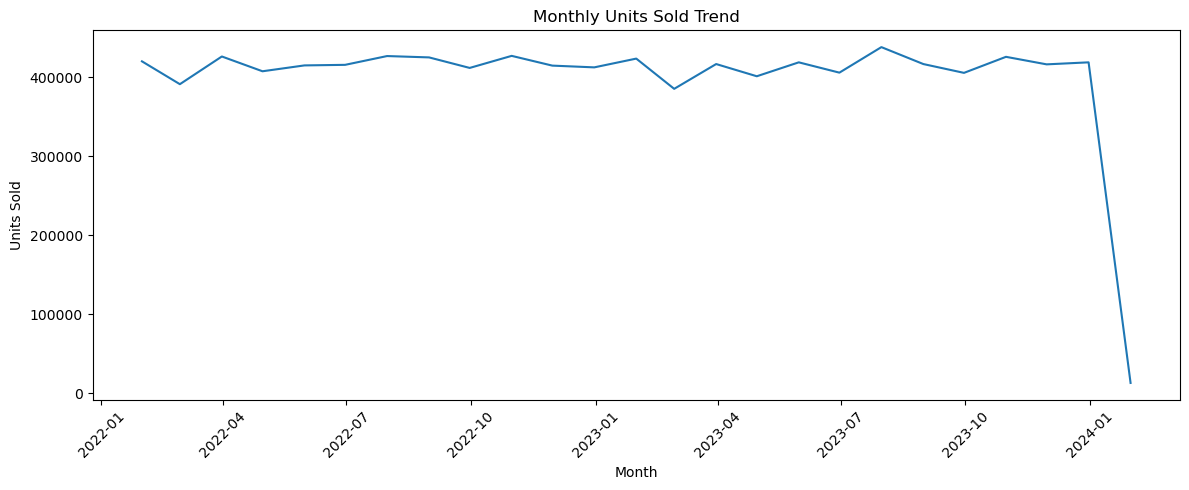

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index, monthly_sales.values)

plt.title("Monthly Units Sold Trend")
plt.xlabel("Month")
plt.ylabel("Units Sold")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
top_products = (
    df.groupby("Product ID")["Units Sold"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(top_products)

Product ID
P0016    508472
P0020    507708
P0014    507622
P0015    507283
P0005    503648
P0009    502086
P0013    500619
P0017    500510
P0011    499362
P0007    499321
Name: Units Sold, dtype: int64


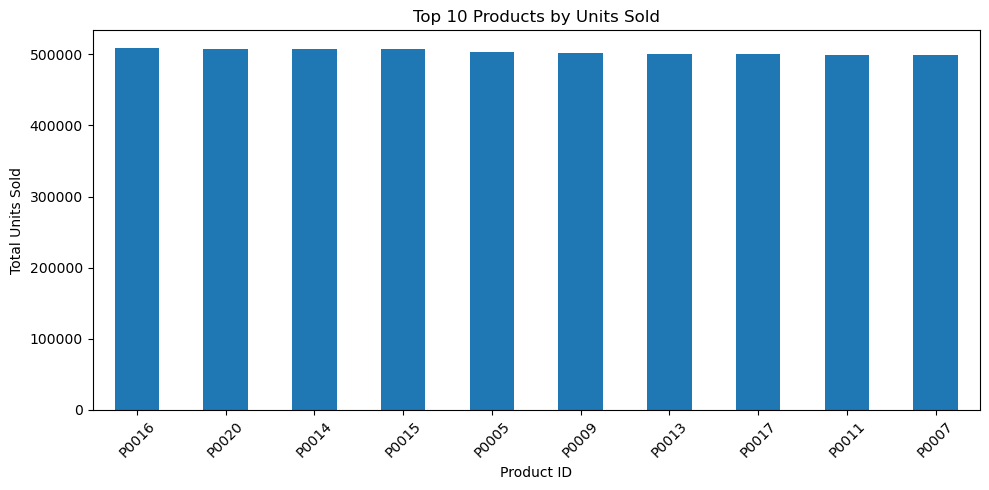

In [12]:
plt.figure(figsize=(10, 5))

top_products.plot(kind="bar")

plt.title("Top 10 Products by Units Sold")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [14]:
category_sales = (
    df.groupby("Category")["Units Sold"]
      .sum()
      .sort_values(ascending=False)
)

print(category_sales)

Category
Furniture      2025017
Groceries      2000482
Clothing       1999166
Toys           1990485
Electronics    1960432
Name: Units Sold, dtype: int64


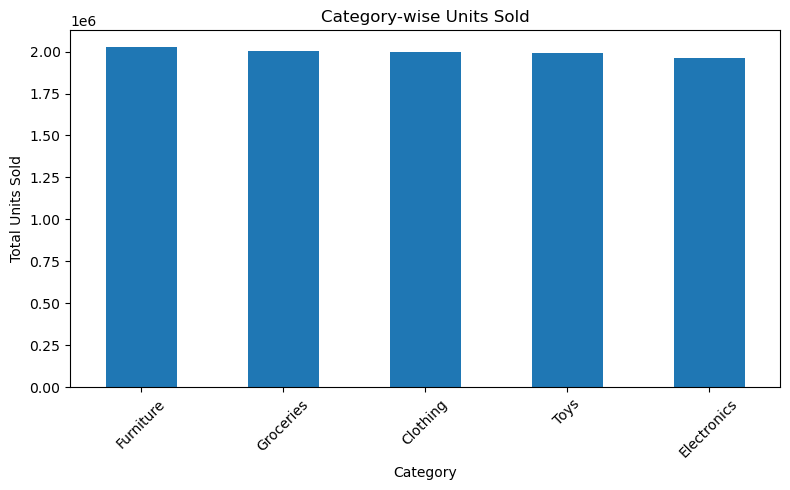

In [15]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar")

plt.title("Category-wise Units Sold")
plt.xlabel("Category")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [16]:
region_sales = (
    df.groupby("Region")["Units Sold"]
      .sum()
      .sort_values(ascending=False)
)

print(region_sales)

Region
East     2511265
South    2507799
North    2484966
West     2471552
Name: Units Sold, dtype: int64


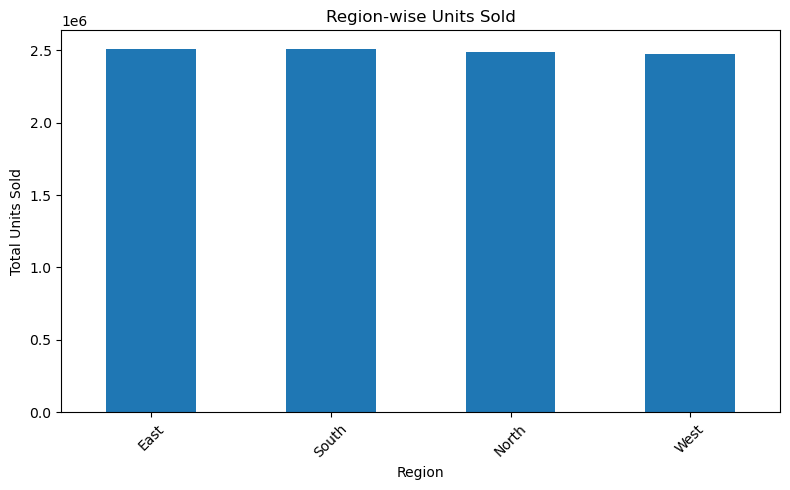

In [17]:
plt.figure(figsize=(8, 5))

region_sales.plot(kind="bar")

plt.title("Region-wise Units Sold")
plt.xlabel("Region")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

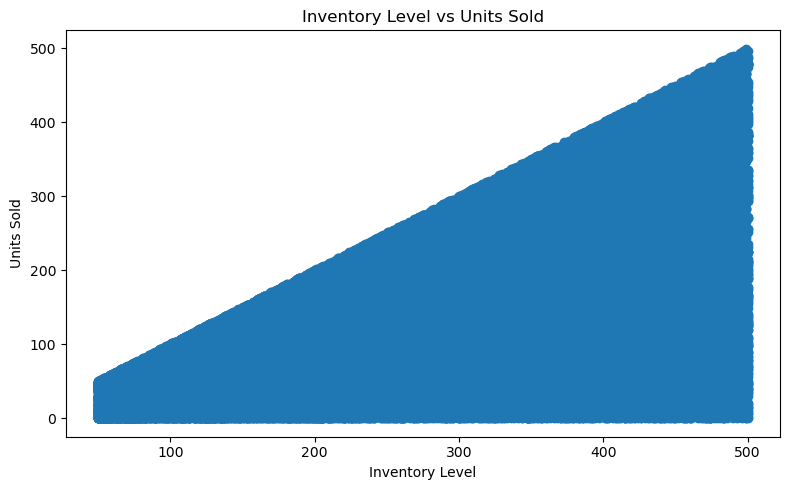

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Inventory Level"], df["Units Sold"])

plt.title("Inventory Level vs Units Sold")
plt.xlabel("Inventory Level")
plt.ylabel("Units Sold")

plt.tight_layout()
plt.show()

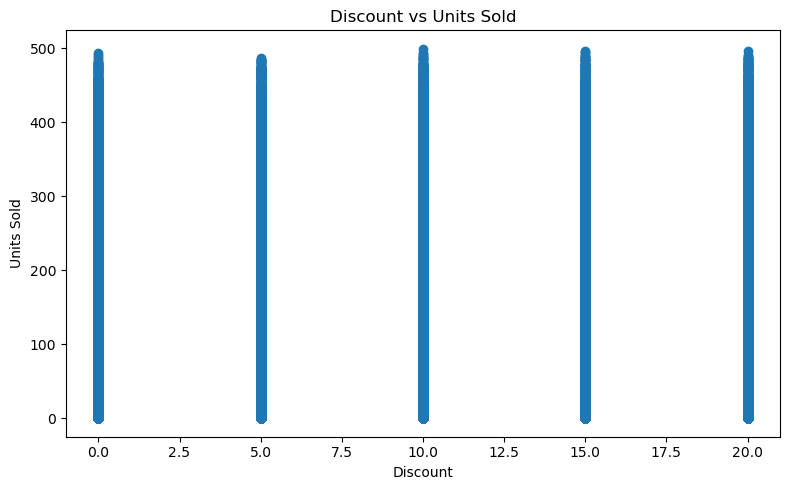

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Discount"], df["Units Sold"])

plt.title("Discount vs Units Sold")
plt.xlabel("Discount")
plt.ylabel("Units Sold")

plt.tight_layout()
plt.show()

In [20]:
promotion_sales = df.groupby("Holiday/Promotion")["Units Sold"].sum()

print(promotion_sales)

Holiday/Promotion
0    5016163
1    4959419
Name: Units Sold, dtype: int64


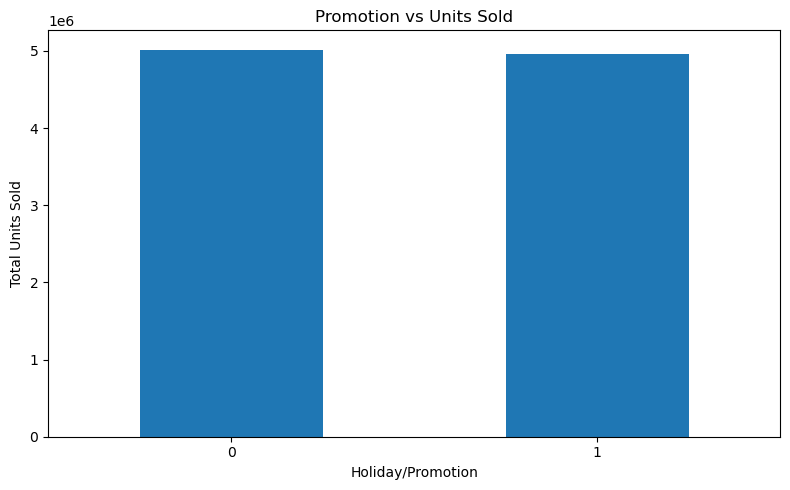

In [21]:
plt.figure(figsize=(8, 5))

promotion_sales.plot(kind="bar")

plt.title("Promotion vs Units Sold")
plt.xlabel("Holiday/Promotion")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [22]:
correlation = df[numerical_cols].corr()

print(correlation)

                    Inventory Level  Units Sold  Units Ordered  \
Inventory Level            1.000000    0.589995       0.001060   
Units Sold                 0.589995    1.000000      -0.000930   
Units Ordered              0.001060   -0.000930       1.000000   
Demand Forecast            0.588561    0.996853      -0.001102   
Price                      0.009140    0.001082       0.004212   
Discount                   0.004889    0.002576      -0.000938   
Holiday/Promotion          0.003411   -0.000374       0.005446   
Competitor Pricing         0.009365    0.001259       0.004596   

                    Demand Forecast     Price  Discount  Holiday/Promotion  \
Inventory Level            0.588561  0.009140  0.004889           0.003411   
Units Sold                 0.996853  0.001082  0.002576          -0.000374   
Units Ordered             -0.001102  0.004212 -0.000938           0.005446   
Demand Forecast            1.000000  0.000675  0.002338          -0.000526   
Price          

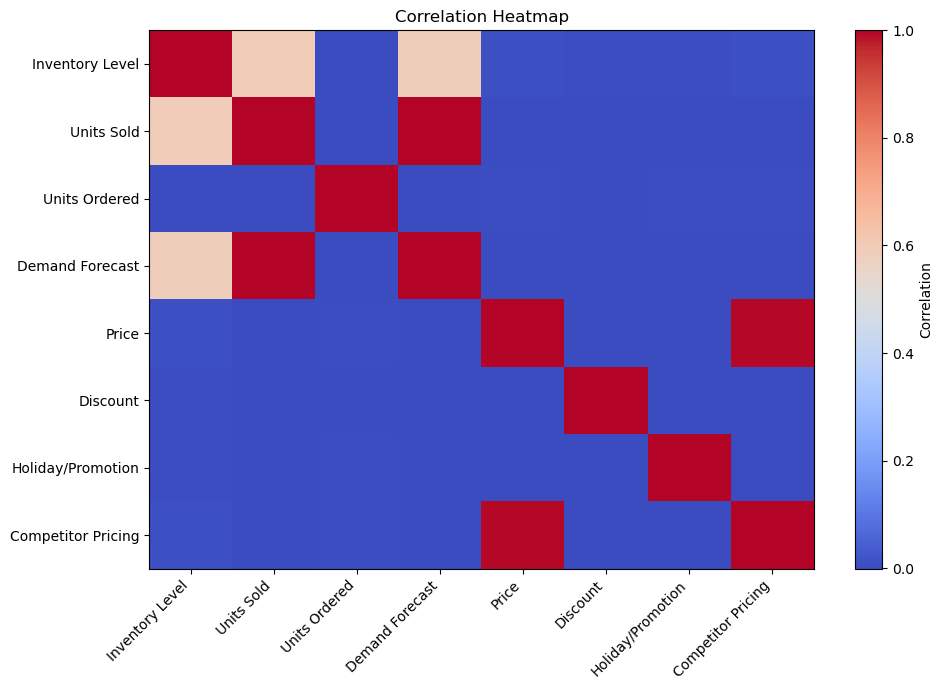

In [23]:
plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap="coolwarm", aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [24]:
print("========== EDA KEY INSIGHTS ==========")

print("\n1. Top 10 Products:")
print(top_products)

print("\n2. Category-wise Sales:")
print(category_sales)

print("\n3. Region-wise Sales:")
print(region_sales)

print("\n4. Promotion-wise Sales:")
print(promotion_sales)

print("\n5. Correlation with Units Sold:")
print(correlation["Units Sold"].sort_values(ascending=False))

========== EDA KEY INSIGHTS ==========

1. Top 10 Products:
Product ID
P0016    508472
P0020    507708
P0014    507622
P0015    507283
P0005    503648
P0009    502086
P0013    500619
P0017    500510
P0011    499362
P0007    499321
Name: Units Sold, dtype: int64

2. Category-wise Sales:
Category
Furniture      2025017
Groceries      2000482
Clothing       1999166
Toys           1990485
Electronics    1960432
Name: Units Sold, dtype: int64

3. Region-wise Sales:
Region
East     2511265
South    2507799
North    2484966
West     2471552
Name: Units Sold, dtype: int64

4. Promotion-wise Sales:
Holiday/Promotion
0    5016163
1    4959419
Name: Units Sold, dtype: int64

5. Correlation with Units Sold:
Units Sold            1.000000
Demand Forecast       0.996853
Inventory Level       0.589995
Discount              0.002576
Competitor Pricing    0.001259
Price                 0.001082
Holiday/Promotion    -0.000374
Units Ordered        -0.000930
Name: Units Sold, dtype: float64


In [ ]:
print("========== EDA FINAL VALIDATION ==========")

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nEDA Objects:")
print("Monthly Sales:", len(monthly_sales))
print("Top Products:", len(top_products))
print("Categories:", len(category_sales))
print("Regions:", len(region_sales))
print("Promotion Groups:", len(promotion_sales))

========== EDA FINAL VALIDATION ==========
Dataset Shape: (73100, 15)
Missing Values: 0
Duplicate Rows: 0

EDA Objects:
Monthly Sales: 25
Top Products: 10
Categories: 5
Regions: 4
Promotion Groups: 2


: 